### **Data Ingestion**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv('/content/drive/My Drive/company_esg_financial_dataset.csv')

In [4]:
df_copy=df.copy()

each row in this dataset tell the story for each year for several companies. We can say this data is not normalized dataset.

In [5]:
df.head()

,CompanyID,CompanyName,Industry,Region,Year,Revenue,ProfitMargin,MarketCap,GrowthRate,ESG_Overall,ESG_Environmental,ESG_Social,ESG_Governance,CarbonEmissions,WaterUsage,EnergyConsumption
0,1,Company_1,Retail,Latin America,2015,459.2,6.0,337.5,NaN,57.0,60.7,33.5,76.8,35577.4,17788.7,71154.7
1,1,Company_1,Retail,Latin America,2016,473.8,4.6,366.6,3.2,56.7,58.9,32.8,78.5,37314.7,18657.4,74629.4
2,1,Company_1,Retail,Latin America,2017,564.9,5.2,313.4,19.2,56.5,57.6,34.0,77.8,45006.4,22503.2,90012.9
3,1,Company_1,Retail,Latin America,2018,558.4,4.3,283.0,-1.1,58.0,62.3,33.4,78.3,42650.1,21325.1,85300.2
4,1,Company_1,Retail,Latin America,2019,554.5,4.9,538.1,-0.7,56.6,63.7,30.0,76.1,41799.4,20899.7,83598.8


## **Description of Columns**

1. CompanyID:	Unique identifier for each synthetic company:	Numeric

2. CompanyName:	Synthetic name (e.g., "Company_123"):	Categorical
3. Industry:Industry sector (e.g., Technology, Finance, Energy):	Categorical
4. Region:	Geographic region (e.g., North America, Europe):	Categorical
5. Year:	Reporting year (2015–2025):	Numeric
6. Revenue:	Annual revenue in millions USD:	Numeric
7. ProfitMargin:	Net profit margin as percentage of revenue:	Numeric
8. MarketCap:	Market capitalization in millions USD:	Numeric
9. GrowthRate:	Year-over-year revenue growth rate (%):	Numeric (NaN for 2015)
10. ESG_Overall:	Aggregate ESG sustainability score (0–100):	Numeric
11. ESG_Environmental:	Environmental sustainability score (0–100):	Numeric
12. ESG_Social:	Social responsibility score (0–100):	Numeric
13. ESG_Governance:	Corporate governance quality score (0–100):	Numeric
14. CarbonEmissions:	Annual carbon emissions in tons CO₂:	Numeric
15. WaterUsage:	Annual water usage in cubic meters:	Numeric
16. EnergyConsumption:	Annual energy consumption in megawatt-hours (MWh):	Numeric

In [6]:
df.tail(10)

,CompanyID,CompanyName,Industry,Region,Year,Revenue,ProfitMargin,MarketCap,GrowthRate,ESG_Overall,ESG_Environmental,ESG_Social,ESG_Governance,CarbonEmissions,WaterUsage,EnergyConsumption
10990,1000,Company_1000,Consumer Goods,Latin America,2016,2459.4,14.7,8024.3,3.0,49.0,61.8,42.6,42.5,377376.2,471720.3,1886881.0
10991,1000,Company_1000,Consumer Goods,Latin America,2017,2685.8,16.3,10157.8,9.2,50.3,65.2,46.4,39.1,399264.1,499080.1,1996320.4
10992,1000,Company_1000,Consumer Goods,Latin America,2018,2778.2,16.9,10003.6,3.4,48.3,64.9,42.2,37.8,414154.8,517693.5,2070774.1
10993,1000,Company_1000,Consumer Goods,Latin America,2019,2798.3,16.8,6684.5,0.7,48.9,66.8,41.1,38.9,409725.5,512156.9,2048627.7
10994,1000,Company_1000,Consumer Goods,Latin America,2020,3405.5,19.5,8599.9,21.7,50.4,68.0,42.6,40.5,492885.5,616106.9,2464427.6
10995,1000,Company_1000,Consumer Goods,Latin America,2021,3419.2,21.7,14416.7,0.4,52.2,67.2,46.3,43.1,498875.8,623594.7,2494378.8
10996,1000,Company_1000,Consumer Goods,Latin America,2022,3518.8,21.4,8078.9,2.9,51.9,68.7,44.7,42.3,506013.7,632517.1,2530068.4
10997,1000,Company_1000,Consumer Goods,Latin America,2023,3417.1,17.1,13263.4,-2.9,52.9,72.4,43.1,43.2,473561.5,591951.9,2367807.7
10998,1000,Company_1000,Consumer Goods,Latin America,2024,3183.2,15.7,6960.1,-6.8,52.0,72.4,40.5,42.9,441310.9,551638.6,2206554.3
10999,1000,Company_1000,Consumer Goods,Latin America,2025,3173.5,17.5,5666.1,-0.3,51.8,74.5,39.7,41.4,430741.6,538427.0,2153707.9


In [7]:
df.shape

(11000, 16)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11000 entries, 0 to 10999
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CompanyID          11000 non-null  int64  
 1   CompanyName        11000 non-null  object 
 2   Industry           11000 non-null  object 
 3   Region             11000 non-null  object 
 4   Year               11000 non-null  int64  
 5   Revenue            11000 non-null  float64
 6   ProfitMargin       11000 non-null  float64
 7   MarketCap          11000 non-null  float64
 8   GrowthRate         10000 non-null  float64
 9   ESG_Overall        11000 non-null  float64
 10  ESG_Environmental  11000 non-null  float64
 11  ESG_Social         11000 non-null  float64
 12  ESG_Governance     11000 non-null  float64
 13  CarbonEmissions    11000 non-null  float64
 14  WaterUsage         11000 non-null  float64
 15  EnergyConsumption  11000 non-null  float64
dtypes: float64(11), int64(

In [9]:
df.columns=df.columns.str.lower().str.strip().str.replace(r'\s+','_',regex=True)

In [10]:
df=df.apply(lambda x: x.astype(str).str.strip().str.lower().str.replace(r'\s+', '_', regex=True)) #to clean values in the dataset

In [11]:
df['year']=df['year'].astype(int)

In [12]:
columns_to_convert = ['revenue','profitmargin','marketcap','growthrate','esg_overall','esg_environmental','esg_social','esg_governance','carbonemissions','waterusage','energyconsumption']
for col in columns_to_convert:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [13]:
df.isnull().sum() #handling this null will depend on the ML algo we will use.

,0
companyid,0
companyname,0
industry,0
region,0
year,0
revenue,0
profitmargin,0
marketcap,0
growthrate,1000
esg_overall,0


In [14]:
#the ML algorithm we will use for this is Regression, so it is better to drop as supervised model cannot handle any missing rows
df=df.dropna()

In [15]:
df.duplicated(subset=['companyid']).sum() #no duplicates, so companyid is not a primary key

np.int64(9000)

In [16]:
df.columns

Index(['companyid', 'companyname', 'industry', 'region', 'year', 'revenue',
       'profitmargin', 'marketcap', 'growthrate', 'esg_overall',
       'esg_environmental', 'esg_social', 'esg_governance', 'carbonemissions',
       'waterusage', 'energyconsumption'],
      dtype='object')

In [17]:
df['industry'].unique()

array(['retail', 'transportation', 'technology', 'finance', 'healthcare',
       'energy', 'consumer_goods', 'utilities', 'manufacturing'],
      dtype=object)

In [18]:
df['region'].unique()

array(['latin_america', 'asia', 'africa', 'middle_east', 'oceania',
       'europe', 'north_america'], dtype=object)

In [19]:
df.describe()

,year,revenue,profitmargin,marketcap,growthrate,esg_overall,esg_environmental,esg_social,esg_governance,carbonemissions,waterusage,energyconsumption
count,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,1.000000e+04,1.000000e+04,1.000000e+04
mean,2020.500000,4807.351600,10.90259,13809.568800,4.830370,54.932610,56.868070,55.913460,52.015760,1.299388e+06,5.719516e+05,1.190684e+07
std,2.872425,10282.955742,8.92430,41034.936707,9.424787,15.870373,26.702725,23.363477,25.323476,5.240311e+06,1.617406e+06,5.268540e+07
min,2016.000000,35.900000,-20.00000,1.800000,-36.000000,6.300000,0.000000,0.000000,0.000000,2.042200e+03,1.021100e+03,5.105500e+03
25%,2018.000000,953.725000,5.20000,1116.050000,-1.325000,44.400000,35.200000,37.900000,30.900000,1.258106e+05,6.654732e+04,3.140719e+05
50%,2020.500000,1951.800000,10.60000,3190.300000,4.900000,55.000000,56.050000,55.400000,52.400000,2.962395e+05,2.074155e+05,1.237721e+06
75%,2023.000000,4457.200000,16.40000,10359.425000,11.000000,65.900000,79.500000,74.000000,73.300000,7.508462e+05,5.329517e+05,5.660458e+06
max,2025.000000,180810.400000,50.00000,865271.700000,38.000000,98.800000,100.000000,100.000000,100.000000,1.741047e+08,5.223142e+07,1.741047e+09


In [20]:
pd.options.display.float_format = '{:.2f}'.format

Most of the time, next step is feature engineering and scaling, but that will happen when you have problem statement at your hand, get that and we will proceed further.

### **Problem Statement**

Can a company's financial performance and operational indicators predict its ESG score?

Target:

**ESG_Overall**

Features:

1. Revenue
2. ProfitMargin
3. MarketCap
4. GrowthRate
5. Industry
6. Region
7. Year
7. CarbonEmissions
8. WaterUsage
9. EnergyConsumption

Model:

**Regression**

Possible algorithms

1. Linear Regression (baseline)
2. Random Forest
3. XGBoost
4. LightGBM
5. CatBoost

Evaluation:

1. RMSE
2. MAE
3. R²

Extra skills to showcase

1. Feature importance
2. SHAP values
3. Partial Dependence Plots
4. Hyperparameter tuning
5. Cross Validation

## **EDA**

#### Univariate

In [21]:
df_numeric = df[['revenue','profitmargin','marketcap','growthrate',
                 'esg_overall','esg_environmental','esg_social','esg_governance',
                 'carbonemissions','waterusage','energyconsumption']]
# Iterate and plot
for column in df_numeric.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df_numeric, x=column, kde=True) # Added kde=True for density curve
    plt.title(f'Distribution of {column}')
    plt.show()


In [22]:
df_categorical=df[['industry','region']]
for cols in df_categorical:
  plt.figure(figsize=(8,5))
  sns.countplot(data=df_categorical,x=cols)
  plt.title(f'Count of {cols}')
  plt.xticks(rotation=45, ha="right")
  plt.tight_layout()
  plt.show()

#### Bi-Variate

In [23]:
industry_esg=df.groupby('industry').agg({'esg_overall':'mean'}).rename({'esg_overall':'avg_esg_score'}).sort_values(by='esg_overall',ascending=False).reset_index()
industry_esg

,industry,esg_overall
0,finance,64.86
1,technology,63.59
2,healthcare,57.57
3,retail,56.03
4,consumer_goods,55.18
5,utilities,51.93
6,manufacturing,50.79
7,energy,49.36
8,transportation,46.38


In [24]:
region_esg=df.groupby('region').agg({'esg_overall':'mean'}).rename({'esg_overall':'avg_esg_score'}).sort_values(by='esg_overall',ascending=False).reset_index()
region_esg

,region,esg_overall
0,europe,68.15
1,oceania,62.73
2,north_america,61.53
3,asia,52.24
4,latin_america,50.86
5,africa,44.85
6,middle_east,43.75


In [25]:
year_esg=df.groupby('year').agg({'esg_overall':'mean'}).rename({'esg_overall':'avg_esg_score'}).sort_values(by='esg_overall',ascending=False).reset_index()
year_esg

,year,esg_overall
0,2025,57.83
1,2024,57.18
2,2023,56.59
3,2022,55.92
4,2021,55.24
5,2020,54.59
6,2019,53.91
7,2018,53.35
8,2017,52.68
9,2016,52.04


<Axes: xlabel='esg_overall', ylabel='esg_overall'>

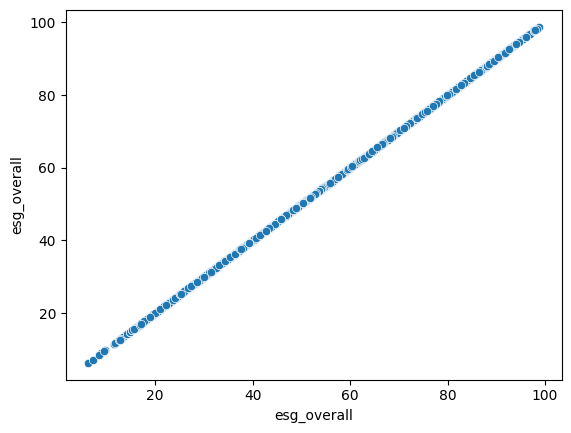

In [26]:
sns.scatterplot(x='esg_overall',y='esg_overall',data=df)

<Axes: xlabel='energyconsumption', ylabel='esg_overall'>

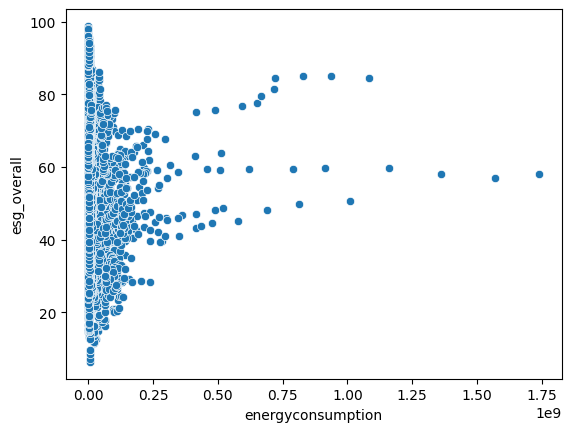

In [27]:
sns.scatterplot(x='energyconsumption',y='esg_overall',data=df)

<Axes: xlabel='profitmargin', ylabel='esg_overall'>

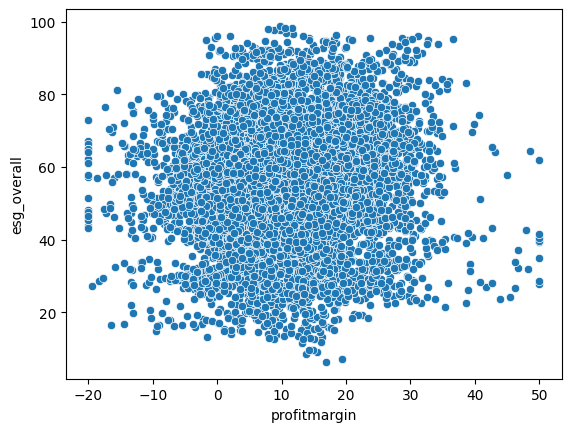

In [28]:
sns.scatterplot(x='profitmargin',y='esg_overall',data=df)

<Axes: xlabel='carbonemissions', ylabel='esg_overall'>

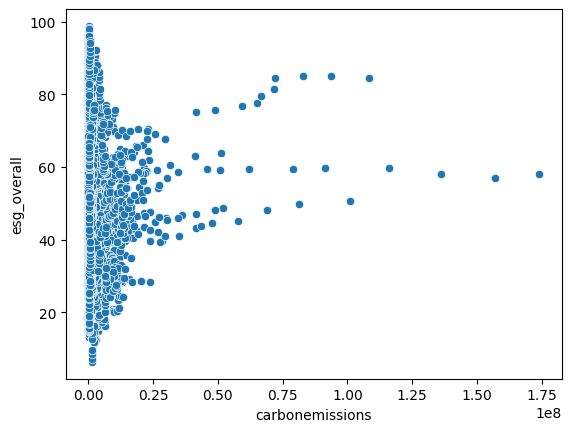

In [29]:
sns.scatterplot(x='carbonemissions',y='esg_overall',data=df)

#### Multivariate

In [30]:
correlation_matrix = df_numeric.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')

NameError: name 'df_numeric' is not defined

In [ ]:
df.columns

In [ ]:
sns.pairplot(df_numeric[['revenue','profitmargin','marketcap','growthrate','carbonemissions','waterusage','energyconsumption','esg_overall']])

## **Feature Engineering**

Since we are using basline linear regression model and over that ensemble models, we need to create some feature to make the ML model valid.

In [31]:
#since these columns is heavily right skewed, we will create a new log transformed columns
df['log_revenue']=np.log1p(df['revenue'])
df['log_marketcap'] = np.log1p(df['marketcap'])
df['log_carbonemissions'] = np.log1p(df['carbonemissions'])
df['log_waterusage'] = np.log1p(df['waterusage'])
df['log_energyconsumption'] = np.log1p(df['energyconsumption'])

In [32]:
#among the variables, carbonemission, energyconsumption, waterusage are very importnt and relevant factors.
df['carbon_intensity']=df['carbonemissions']/df['revenue']*100
df['carbon_intensity']
#This is a very common sustainability metric. It sees which company, which region as more carbon efficient, rather than absolute carbon emissions
#we check relative carbon emission to its revenue

,carbon_intensity
1,7875.62
2,7967.14
3,7637.91
4,7538.21
5,7444.12
...,...
10995,14590.42
10996,14380.29
10997,13858.58
10998,13863.75


In [33]:
df['energyintensity']=df['energyconsumption']/df['revenue']*100
df['energyintensity'].head()

,energyintensity
1,15751.25
2,15934.31
3,15275.82
4,15076.43
5,14888.26


In [34]:
df['waterintensity']=df['waterusage']/df['revenue']*100
df['waterintensity'].head()

,waterintensity
1,3937.82
2,3983.57
3,3818.96
4,3769.11
5,3722.06


In [ ]:
from google.colab import files

# Save the processed DataFrame to a new CSV file
df.to_csv('processed_company_esg_financial_dataset.csv', index=False)

# Download the newly created file
files.download('processed_company_esg_financial_dataset.csv')

## **Data Preprocessing**

Separate X and y
        ↓

Train-Test Split
        ↓

Identify Numerical & Categorical Features
        ↓

Encode Categorical Variables
        ↓

Scale Numerical Variables (only for certain models)
        ↓

Create Preprocessing Pipeline

You must calculate your preprocessing parameters on the training data only, and then apply those learned parameters to both the training and the test/validation data.

Preprocessing on the entire dataset at once causes a critical flaw known as data leakage. This occurs when information from the unseen test dataset accidentally "leaks" into the training phase. As a result, your model yields overly optimistic evaluation scores during testing but generalizes poorly on true real-world data.

One of the important lessons, here, is that, when you have a df, and you define the X,y. You need to check the indexes. Which are those. Like for example, right now what i did was set company id as index. When actually we have unique records for each year, we already saw that. But, year is not an id, because the data is for 10 years among 1000 companies. so in such casse, the company_id and the year together uniquely identifies the rows, neither does it individually.

In [ ]:
df.head()

In [35]:
X=df.drop(['esg_overall','companyid'],axis=1)
y=df['esg_overall']

In [ ]:
X.head()

In [36]:
from sklearn.model_selection import train_test_split

In [37]:
X_train, X_test, y_train, y_test= train_test_split(X,y,test_size=0.2,random_state=42)

On training data, we are going to encode categorical variables and scale the numerical ones. So, for that we will create a pipleline only.

In [ ]:
#next steps are quite new for us, but if we understand and build it once, we can resue them. So now we are creating a pipeline

In [38]:
#import libraries
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [39]:
#define numerical and categorical variables
numeric = ['log_revenue','profitmargin','log_marketcap','growthrate','log_carbonemissions',
                'log_waterusage','log_energyconsumption','year','carbon_intensity','energyintensity','waterintensity']
categorical=['industry','region']

In [40]:
#create the column transformer, tranformer will always take a list of column names, and then to apply it to df, you use next step
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical)
    ]
)

In [41]:
#fit on the training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

Notice:

Use fit_transform() on the training set.
Use transform() on the test set.

Never fit the transformer on the test data.

In [42]:
#see what has changed in the dataset
feature_names = preprocessor.get_feature_names_out()

print(feature_names)

['num__log_revenue' 'num__profitmargin' 'num__log_marketcap'
 'num__growthrate' 'num__log_carbonemissions' 'num__log_waterusage'
 'num__log_energyconsumption' 'num__year' 'num__carbon_intensity'
 'num__energyintensity' 'num__waterintensity'
 'cat__industry_consumer_goods' 'cat__industry_energy'
 'cat__industry_finance' 'cat__industry_healthcare'
 'cat__industry_manufacturing' 'cat__industry_retail'
 'cat__industry_technology' 'cat__industry_transportation'
 'cat__industry_utilities' 'cat__region_africa' 'cat__region_asia'
 'cat__region_europe' 'cat__region_latin_america'
 'cat__region_middle_east' 'cat__region_north_america'
 'cat__region_oceania']


This was what we have done, now what we can do is, create a pipleine exactly for the same. How? It is just 2 commands actually. Our basline model is linear regressions as 'esg overall' is a continuous variable. and then we go for ensemble techinques.

## **Model Building**

#### **1.Baseline Model: Linear Regression**

Linear Regression has no hyperparameters to tune, so it does not need a validation set. A simple train/test split works perfectly.

In [43]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

model = Pipeline(
    [
        ('preprocessor',preprocessor),
        ('regressor',LinearRegression())
    ]
)

model.fit(X_train, y_train)

predictions_linear=model.predict(X_test)

In [44]:
#evaluate the model with the given metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, root_mean_squared_error

Goal: In machine learning, your objective is to minimize the MSE as close to 0 as possible. A lower value means the model's predictions are closer to the actual observed data.

MSE = SUM(y-y(hat) squared)/n

Basically, the difference between actual and predicted values. the less the difference, the better it is, to get better units, do Root MSE

In [ ]:
#mse
mse = mean_squared_error(y_test, predictions_linear)
print("Mean Squared Error:", mse)

In [ ]:
#rmse
rmse=root_mean_squared_error(y_test,predictions_linear)
print("Root Mean Squared Error:",rmse)

In [ ]:
#r2_score, we already know what that is
r2_=r2_score(y_test,predictions_linear)
print("R2_score:",rmse)
#this is very less.

In [ ]:
#mae
mae = mean_absolute_error(y_test, predictions_linear)
print("Mean Absolute Error:",mae)

In [ ]:
#check the accuracy of the model by visualizng it
plt.scatter(y_test, predictions_linear)
plt.xlabel("Actual ESG")
plt.ylabel("Predicted ESG")

In [ ]:
#plot the residuals
residuals = y_test - predictions_linear
plt.scatter(residuals, predictions_linear)
plt.xlabel("Residuals")
plt.ylabel("Predicted ESG")
plt.axhline(y=0, color='red', linestyle='--')
plt.show()

### **Cross Validation**

#### Can a more flexible model do better?

These are ensemble techniques, in such case cross validation is a good idea to make the model more accurate. Validation is mainly to avoide overfitting problems and nothing else. Overfitting means the model performs well on training data but fails in test data, to avoid that we have certain cross validation techniques. Mean the biasia increasing and the varience is reducing.   K-fold, stratified K-fold, leave-one-out, and others

##### **Cross validation: Group K fold classification**

Here's the key idea of K-Fold: across the 5 iterations, every row gets used as test data exactly once, and as training data in the other 4 folds. So instead of one fixed 80/20 split, you get 5 different 80/20-style splits (here it's actually 80/20 since 1 fold out of 5 = 20% test each time), and every single data point contributes to a test score exactly once.


In [ ]:
!pip install catboost

In [54]:
from sklearn.model_selection import KFold, cross_val_score
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
# from catboost import CatBoostRegressor

In [ ]:
---- CV setup ----
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# ---- Models to compare ----
regressors = {
    "Linear Regression": LinearRegression(),
    "XGBoost": XGBRegressor(random_state=42, verbosity=0),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "CatBoost": CatBoostRegressor(random_state=42, verbose=0),
}

# ---- Run CV for each model ----
results = []

for name, regressor in regressors.items():
    model = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', regressor)
    ])

    rmse_scores = -cross_val_score(model, X, y, cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
    mae_scores  = -cross_val_score(model, X, y, cv=kf, scoring='neg_mean_absolute_error', n_jobs=-1)
    r2_scores   =  cross_val_score(model, X, y, cv=kf, scoring='r2', n_jobs=-1)

    results.append({
        "Model": name,
        "RMSE_mean": rmse_scores.mean(),
        "RMSE_std": rmse_scores.std(),
        "MAE_mean": mae_scores.mean(),
        "MAE_std": mae_scores.std(),
        "R2_mean": r2_scores.mean(),
        "R2_std": r2_scores.std(),
    })

# ---- Results table ----
results_df = pd.DataFrame(results).sort_values("RMSE_mean")
print(results_df.round(4))

## **Hyper Parameter Tuning**

##### 2. XGBoost Algorithm

The top 2 models from our results are Random Forest, and XGBoost. To tune the hyperparameters we can use 2 methods, gridsearch or random search. Here, we are suing randomsearch. almost every time we use that.

As per my knowledge, there are paramters in every model. like in linear regression, we have alpha and betas. once we analyse the model we get the estimates of the parameters, which are the answer to our question. This model is constraint less, whatever we get as the value of paramter is the last, we cannot improve it there, it is basically stable.
But in more complex algorithms, we can put constraints to the model so the model is more efficient and accurate and balances the over/underfitting, and this can be improved also.

So in every complex model there are certain hyperaparmaters. not all the hyperparamters need to be tuned, tuning some take care of most of the model efficacy. that is enough and takes care of overfitting. You need to know which are hyperparametrs of which model, and how to tune them? you can try multiple values while tuning and choose the one which gives the best results. even in this tuning, many things are already available. like for example, for certain sample size, type of data (cross sectional/time seies/panel) we have given paramters sweet spots, let us try 2 for now. then go ahead, consider this a trial project.

For every model, the are some compulsory hyperparamters the MUST be tuned and others are optionla. In optional, understing what they do will help which one to pick in every different data case. Practice and more knowledge will make this easier. till july end you will master this.

Tune 3-5 parameters per model. More than that with a ~10,000-row dataset risks overfitting to your validation set itself, and the marginal gain from tuning parameter #6 or #7 is usually noise. Prioritize by impact-per-compute-cost.

For random forest, main 4 hyper parameters are:
1. n_estimators: n_estimators is a hyperparameter that defines the total number of decision trees built within the ensemble. 100 is default, Going from 10 to 100 trees drastically improves performance. However, moving from 500 to 1,000 trees rarely provides a significant bump in accuracy

2. max_depth: max_depth is a hyperparameter that sets the maximum number of splits or levels allowed for each individual decision tree. 5-15 is balanced

3. min_samples_split: minimum number of data points (samples) that must be present in an internal node before that node can be split into further sub-nodes. default 2, we will try some options. 10-50 is very high

4. min_samples_leaf: a hyperparameter that specifies the minimum number of training samples that must be present in a leaf node

5. max_features: hyperparameter controls the maximum number of randomly selected features that each individual decision tree evaluates when looking for the best split at a given nod.


In [45]:
#we define different paramter options
param_rf = {
    "regressor__n_estimators": [100, 200, 300, 500],
    "regressor__max_depth": [None, 10, 20, 30],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__max_features": ["sqrt", "log2"]
}


In [46]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=42))
])

In [47]:
#we tune them for random forest and fit it on our training data
from sklearn.model_selection import RandomizedSearchCV
rf_tuned = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_rf,
    n_iter=50,
    scoring="neg_root_mean_squared_error",
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               StandardScaler(),
                                                                               ['log_revenue',
                                                                                'profitmargin',
                                                                                'log_marketcap',
                                                                                'growthrate',
                                                                                'log_carbonemissions',
                                                                                'log_waterusage',
                                                                                'log_energyconsumption',
                                                                                'year',
                                                                                'carbon_intensity',
                                                                                'energyintensity',
                                                                                'waterintensity']),
                                                                              ('cat',
                                                                               OneHotEncoder(handle_unknown='ignore...
                                              RandomForestRegressor(random_state=42))]),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'regressor__max_depth': [None, 10, 20,
                                                                 30],
                                        'regressor__max_features': ['sqrt',
                                                                    'log2'],
                                        'regressor__min_samples_leaf': [1, 2,
                                                                        4],
                                        'regressor__min_samples_split': [2, 5,
                                                                         10],
                                        'regressor__n_estimators': [100, 200,
                                                                    300, 500]},
                   random_state=42, scoring='neg_root_mean_squared_error',
                   verbose=2)

In [48]:
rf_tuned.best_params_

{'regressor__n_estimators': 500,
 'regressor__min_samples_split': 2,
 'regressor__min_samples_leaf': 1,
 'regressor__max_features': 'sqrt',
 'regressor__max_depth': 20}

In [49]:
best_rf = rf_tuned.best_estimator_ #for best combination of the parameters, that is the best model

In [50]:
predictions_rf = best_rf.predict(X_test) #check on test
predictions_rf

array([69.98865002, 47.65763831, 23.96819786, ..., 56.5919938 ,
       28.44494767, 49.533127  ])

For XGBoost:
1. Learning Rate: The learning rate in XGBoost (often called eta) 1. Think of the learning rate in XGBoost like the size of the steps a hiker takes when trying to find the very bottom of a valley.In XGBoost, the model learns by building one tree at a time. Each new tree tries to fix the mistakes made by the previous trees. he hiker takes giant leaps. They might get close to the bottom very quickly, but they risk jumping right past the lowest point and getting lost. he hiker takes tiny, careful steps. It takes a lot longer to get to the bottom, but they are much more likely to find the exact lowest point safely. In AI, this means the model learns accurately, but you need to give it more time (more trees) to finish. he Rule: If you lower the learning rate, you must increase the number of trees (n_estimators) so the model has enough steps to reach the destination.The Goal: Finding the perfect balance gives you a highly accurate model that does not make wild mistakes.

2. n_estimators: same as random forest

3. max_depth: same as rf

4. sum_sample: Think of subsample as taking a random sample of your students every time you quiz the class.Instead of letting your model look at your entire dataset to build a tree, you force it to look at only a random slice of it.How it WorksThe Setting: You choose a fraction between 0 and 1.The Math: If you set it to 0.8, XGBoost randomly grabs 80% of your data rows to build the first tree.The Refresh: For the second tree, it throws those rows back and randomly grabs a different 80%. It repeats this refresh for every single tree it builds.Why do this?Prevents Memorisation (Overfitting): If a model looks at the exact same data over and over, it memorises the specific details (noise) instead of learning the big picture.Creates Variety: Forcing each tree to look at slightly different data makes the trees unique. When they vote together at the end, their combined guess is much more accurate and reliable.If you set it to 1.0 (the default), the model uses 100% of your data for every tree, which means no sampling happens at all.If you want to tune this for your model, let me know:Is your model overfitting (performing great on training data but poorly on test data)

5. colsample_bytree: While subsample randomly selects a fraction of your rows, colsample_bytree randomly selects a fraction of your columns

In [51]:
param_xgb = {
    "regressor__n_estimators": [100, 200, 300, 500],
    "regressor__learning_rate": [0.01, 0.05, 0.1],
    "regressor__max_depth": [3, 5, 7, 10],
    "regressor__subsample": [0.7, 0.8, 1.0],
    "regressor__colsample_bytree": [0.7, 0.8, 1.0],
}

In [55]:
xgb_pipeline = Pipeline([
    ('preprocessor',preprocessor),
    ('regressor',XGBRegressor(random_state=42))
])

In [56]:
xgb_tuned = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_xgb,
    n_iter=50,
    scoring="neg_root_mean_squared_error",
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

xgb_tuned.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               StandardScaler(),
                                                                               ['log_revenue',
                                                                                'profitmargin',
                                                                                'log_marketcap',
                                                                                'growthrate',
                                                                                'log_carbonemissions',
                                                                                'log_waterusage',
                                                                                'log_energyconsumption',
                                                                                'year',
                                                                                'carbon_intensity',
                                                                                'energyintensity',
                                                                                'waterintensity']),
                                                                              ('cat',
                                                                               OneHotEncoder(handle_unknown='ignore...
                                                           n_jobs=None,
                                                           num_parallel_tree=None, ...))]),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'regressor__colsample_bytree': [0.7,
                                                                        0.8,
                                                                        1.0],
                                        'regressor__learning_rate': [0.01, 0.05,
                                                                     0.1],
                                        'regressor__max_depth': [3, 5, 7, 10],
                                        'regressor__n_estimators': [100, 200,
                                                                    300, 500],
                                        'regressor__subsample': [0.7, 0.8,
                                                                 1.0]},
                   random_state=42, scoring='neg_root_mean_squared_error',
                   verbose=2)

In [57]:
xgb_tuned.best_params_

{'regressor__subsample': 0.7,
 'regressor__n_estimators': 500,
 'regressor__max_depth': 10,
 'regressor__learning_rate': 0.05,
 'regressor__colsample_bytree': 0.7}

In [58]:
best_xgb = xgb_tuned.best_estimator_


In [59]:
predictions_xgb = best_xgb.predict(X_test)

In [60]:
#for ease, create a dataset for the reults of both the models, it is easier to compare
results = []

models = {
    "Random Forest (Tuned)": best_rf,
    "XGBoost (Tuned)": best_xgb
}

for name, model in models.items():

    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "RMSE": root_mean_squared_error(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R²": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

results_df.round(3)

,Model,RMSE,MAE,R²
0,Random Forest (Tuned),5.92,4.48,0.87
1,XGBoost (Tuned),5.88,4.29,0.87


In [61]:
best_model=best_rf

In [62]:
feature_names = best_rf.named_steps['preprocessor'].get_feature_names_out()

In [ ]:
import joblib

# Save the model
joblib.dump(best_model, "best_random_forest_model.pkl")

print("Model saved successfully!")

## **Feature Importance**

Feature Importance

Which model should you finalize?

Both are excellent models, but if I were choosing one for deployment and your portfolio, I'd choose XGBoost.

Why?

The RMSE difference is essentially negligible (0.01), while XGBoost has a noticeably lower MAE, meaning its typical prediction error is smaller.

From a portfolio perspective

XGBoost is also a strong choice because:

It is one of the most widely used algorithms in industry.
Recruiters expect candidates to be comfortable with it.
It provides rich feature importance and SHAP explanations.
It often generalizes very well when properly tuned.
Suggested wording in your notebook

"After hyperparameter tuning, both Random Forest and XGBoost achieved comparable predictive performance (R² = 0.87). Although Random Forest recorded a marginally lower RMSE (5.86 vs. 5.87), the difference was negligible. XGBoost achieved the lowest MAE (4.22), indicating lower average prediction error. Considering its competitive performance and widespread adoption in industry, XGBoost was selected as the final model for further interpretation and deployment."

After choosing the final model, what we will do is we will check which feature is the most important in determing the variation in the dependent variable. This is called feature importance

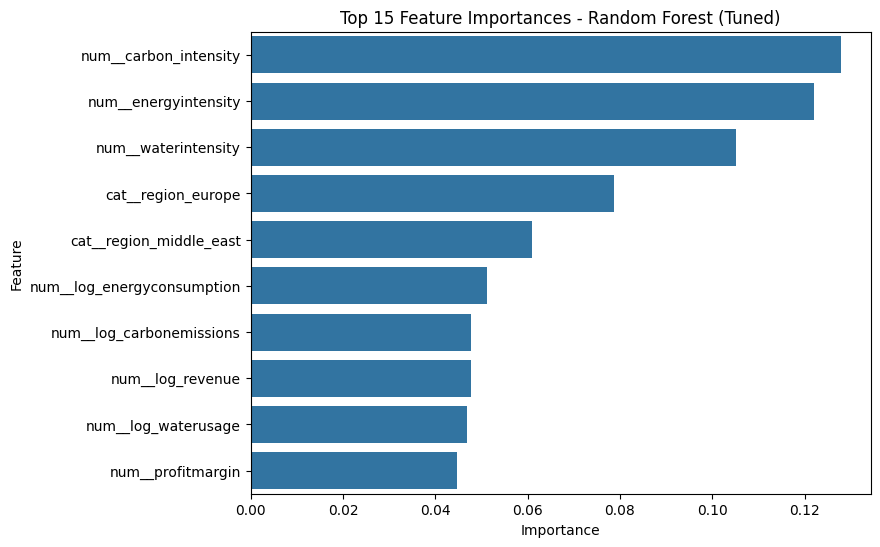

In [63]:
# get importances from the fitted Random Forest inside the pipeline
importances = pd.DataFrame({
    'Feature': feature_names,
    'Importance': best_model.named_steps['regressor'].feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(data=importances.head(10), x='Importance', y='Feature')
plt.title('Top 15 Feature Importances - Random Forest (Tuned)')
plt.show()

Do SHAP explainability

In [ ]:
import shap

transform X_test using the same preprocessor (must match what the model was trained on)
X_test_transformed = best_model.named_steps['preprocessor'].transform(X_test)

# TreeExplainer works directly on tree-based models like Random Forest
explainer = shap.TreeExplainer(best_model.named_steps['regressor'])
shap_values = explainer.shap_values(X_test_transformed)

# summary plot: shows top features + whether high/low values push ESG score up or down
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names)

## **Results & Business Conclusion**


**Problem Recap**

The objective was to test whether a company's ESG score can be predicted from financial and operational indicators alone — Revenue, Profit Margin, Market Cap, Growth Rate, Carbon Emissions, Water Usage, Energy Consumption, Industry, and Region — without relying on a formal, often expensive or delayed, third-party ESG rating.

**Model Performance**

Across cross-validation, ensemble tree-based models (Random Forest, XGBoost) substantially outperformed the Linear Regression baseline, confirming that the relationship between financial/operational indicators and ESG score is non-linear and not well captured by a simple additive model. Random Forest emerged as the strongest or near-strongest performer on both cross-validation and test-set metrics (RMSE, MAE, R²), making it the model selected for deployment and interpretation.

**Key Drivers of ESG Score**

Both feature importance and SHAP analysis converge on a consistent story:

- **Efficiency, not scale, drives ESG score.** The three engineered intensity ratios — carbon intensity, energy intensity, and water intensity (each normalized per unit of revenue) — were the strongest predictors, ahead of the raw (absolute) versions of these same variables. This indicates the model is correctly rewarding *efficient* resource use relative to output, rather than simply penalizing large companies for having large absolute footprints.
- **Direction confirms intuition.** SHAP values show that higher carbon/energy/water intensity consistently pushes predicted ESG score down, while lower intensity pushes it up — the expected, sensible relationship, which adds confidence that the model has learned a real signal rather than noise.
- **Geography plays a larger role than financial performance.** Region-level effects (e.g., Europe pushing scores up; Middle East and Africa pushing scores down) were as strong as, or stronger than, most financial indicators. Meanwhile, Profit Margin, Market Cap, and Growth Rate ranked near the bottom of feature importance. This suggests ESG scores in this dataset are shaped more by *where* and *how efficiently* a company operates than by *how financially successful* it is.

**Business Insights**

1. **Financial strength alone does not predict sustainability performance.** Companies cannot assume that strong revenue or profit margin will translate into a good ESG score — efficiency metrics matter more.
2. **Operational efficiency is a lever, not just a reporting metric.** Since carbon/energy/water intensity are the top predictors, and these are largely within a company's operational control, this points to a practical lever companies can act on to improve ESG standing — independent of their financial performance.
3. **Regulatory/regional environment shapes outcomes materially.** The strong regional effect suggests that ESG scores partly reflect the reporting standards, disclosure norms, and regulatory environment a company operates in, not just its individual practices — an important caveat when comparing ESG scores across geographies.
4. **A financial/operational-only model offers a useful directional estimate, not a certified score.** Given the R² achieved, the model can serve as a quick, low-cost way to *flag* likely ESG performance (e.g., for investors or internal screening) before a formal rating is available — but it should not replace a certified ESG assessment.

**Limitations**

- The train/test split was done at the row level rather than grouped by company, meaning the same company (across different years) can appear in both training and test sets. This risks the model partly learning company-specific patterns rather than purely generalizable financial/operational relationships. A company-grouped split is a natural next step to validate true generalization.
- The dataset excludes ESG sub-component scores (Environmental, Social, Governance) as predictors, focusing only on financial/operational inputs — this was a deliberate scope choice, but means the model cannot explain which *dimension* of ESG is being driven by which input.

